# Visualização de Dados — E-commerce de Moda

**Objetivo:** explorar a base `ecommerce_estatistica.csv` (resultado dos exercícios anteriores) com gráficos que ajudem o cliente a entender **preços, avaliações, descontos e volume de vendas** dos produtos.

Gráficos produzidos:
1. Histograma — distribuição de preços
2. Dispersão — preço × nota
3. Mapa de calor — correlação entre variáveis numéricas
4. Barras — marcas que mais vendem
5. Pizza — participação por público (gênero)
6. Densidade — preço por gênero
7. Regressão — avaliações × quantidade vendida

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'

## 1. Leitura e entendimento dos dados

In [2]:
df = pd.read_csv('../data/ecommerce_estatistica.csv')
df = df.drop(columns=['Unnamed: 0'])
print(df.shape)
df.head()

(295, 23)


,Título,Nota,N_Avaliações,Desconto,Marca,Material,Gênero,Temporada,Review1,Review2,...,Nota_MinMax,N_Avaliações_MinMax,Desconto_MinMax,Preço_MinMax,Marca_Cod,Material_Cod,Temporada_Cod,Qtd_Vendidos_Cod,Marca_Freq,Material_Freq
0,Kit 10 Cuecas Boxer Lupo Cueca Box Algodão Mas...,4.5,3034.0,18.0,lupo,algodão,Masculino,outono/inverno,As cuecas são boas; porém você percebe na cost...,"Pelo preço promocional, com ctz tem algum defe...",...,0.814815,0.334178,0.213115,0.378585,463,25,3,10000.0,0.042292,0.176444
1,Kit Com 10 Cuecas Boxer Algodão Sem Costura Zo...,4.7,5682.0,20.0,zorba,algodão,Masculino,não definido,O tecido é bom e são confortáveis. Só que a nu...,Vendo comentários de outros consumidores vejo ...,...,0.888889,0.625937,0.245902,0.322329,838,25,1,50000.0,0.009095,0.176444
2,Kit 10 Cuecas Boxer Mash Algodão Cotton Box Or...,4.6,1700.0,22.0,mash,algodão,Masculino,primavera/verão,"As cuecas são boas, porém meu marido usa g e p...","E o tamanho certo, mas em baixo dela, fica mui...",...,0.851852,0.187197,0.278689,0.372617,494,25,7,10000.0,0.010914,0.176444
3,Kit 3 Short Jeans Feminino Cintura Alta Barato...,4.4,507.0,9.0,menina linda,jean,Feminino,primavera/verão,Estou encantada com essas peças!.\nOs shorts s...,"Recomendo, tecido confortável, igual a foto.",...,0.777778,0.055751,0.065574,0.201767,509,74,7,1000.0,0.010005,0.025466
4,Blusa + Calça Térmica Treino Futebol Criança I...,4.7,58.0,5.0,roupa zero grau,termico unissex,Sem gênero infantil,outono/inverno,"Produto ótimo , mesmo após várias lavagens não...",Produto de boa qualidade.\nNão gruda pêlos e n...,...,0.888889,0.006280,0.000000,0.114508,669,166,3,100.0,0.002274,0.000910


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 295 entries, 0 to 294
Data columns (total 23 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Título               295 non-null    str    
 1   Nota                 295 non-null    float64
 2   N_Avaliações         295 non-null    float64
 3   Desconto             295 non-null    float64
 4   Marca                295 non-null    str    
 5   Material             295 non-null    str    
 6   Gênero               295 non-null    str    
 7   Temporada            295 non-null    str    
 8   Review1              295 non-null    str    
 9   Review2              295 non-null    str    
 10  Review3              295 non-null    str    
 11  Qtd_Vendidos         295 non-null    str    
 12  Preço                295 non-null    float64
 13  Nota_MinMax          295 non-null    float64
 14  N_Avaliações_MinMax  295 non-null    float64
 15  Desconto_MinMax      295 non-null    float64
 16  P

In [4]:
df[['Nota', 'N_Avaliações', 'Desconto', 'Preço', 'Qtd_Vendidos_Cod']].describe().round(2)

,Nota,N_Avaliações,Desconto,Preço,Qtd_Vendidos_Cod
count,295.00,295.00,295.00,295.00,295.00
mean,4.48,490.51,16.01,130.84,2946.31
std,0.32,1079.40,9.93,64.23,8068.02
min,2.30,3.00,5.00,25.63,5.00
25%,4.30,19.00,9.00,73.34,100.00
50%,4.50,77.00,11.00,129.21,100.00
75%,4.70,326.00,22.00,179.90,1000.00
max,5.00,9077.00,51.00,326.55,50000.00


### Ajustes para a análise
- `Qtd_Vendidos` é uma faixa em texto (`+100`, `+10mil`...). A versão numérica `Qtd_Vendidos_Cod` representa o **limite inferior** da faixa, então é uma estimativa conservadora de vendas.
- `Gênero` tem categorias pequenas e infantis; agrupo em públicos maiores para leitura mais clara.

In [5]:
def agrupar_genero(g):
    if g in ['Masculino']:
        return 'Masculino'
    if g in ['Feminino']:
        return 'Feminino'
    if g in ['Meninos', 'Meninas', 'Sem gênero infantil', 'Bebês']:
        return 'Infantil'
    return 'Sem gênero / Unissex'

df['Público'] = df['Gênero'].apply(agrupar_genero)
df['Público'].value_counts()

Público
Masculino               129
Feminino                114
Sem gênero / Unissex     27
Infantil                 25
Name: count, dtype: int64

## 2. Histograma — distribuição de preços

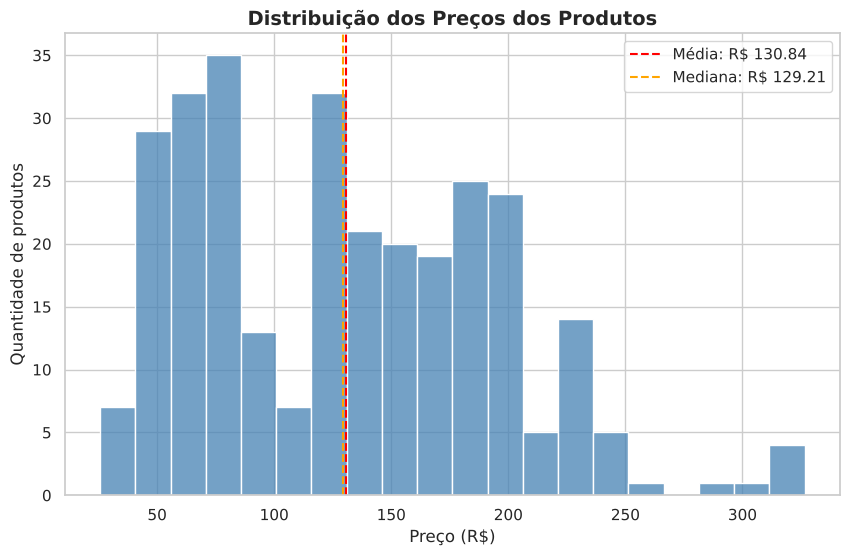

In [6]:
fig, ax = plt.subplots()
sns.histplot(df['Preço'], bins=20, color='steelblue', ax=ax)
ax.axvline(df['Preço'].mean(), color='red', ls='--', label=f"Média: R$ {df['Preço'].mean():.2f}")
ax.axvline(df['Preço'].median(), color='orange', ls='--', label=f"Mediana: R$ {df['Preço'].median():.2f}")
ax.set_title('Distribuição dos Preços dos Produtos')
ax.set_xlabel('Preço (R$)')
ax.set_ylabel('Quantidade de produtos')
ax.legend()
plt.show()

**Leitura:** a maior parte dos produtos está na faixa intermediária de preço, com média e mediana próximas — sinal de distribuição pouco assimétrica. Poucos produtos passam de R$ 250, o que indica um catálogo concentrado em ticket médio.

## 3. Gráfico de dispersão — preço × nota

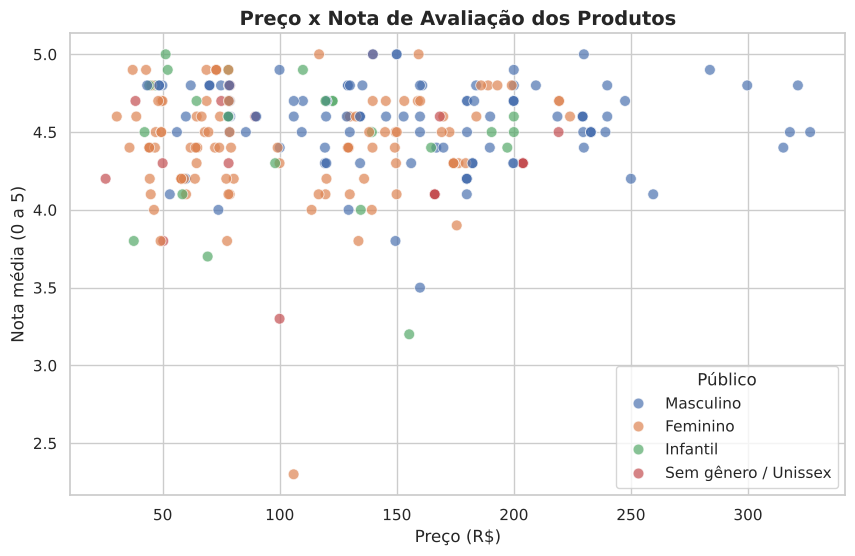

Correlação Preço x Nota: 0.01


In [7]:
fig, ax = plt.subplots()
sns.scatterplot(data=df, x='Preço', y='Nota', hue='Público', alpha=0.7, s=60, ax=ax)
ax.set_title('Preço x Nota de Avaliação dos Produtos')
ax.set_xlabel('Preço (R$)')
ax.set_ylabel('Nota média (0 a 5)')
ax.legend(title='Público')
plt.show()

print(f"Correlação Preço x Nota: {df['Preço'].corr(df['Nota']):.2f}")

**Leitura:** os pontos não formam tendência — a correlação é praticamente zero. **Cobrar mais caro não está associado a notas melhores (nem piores)**: a satisfação do cliente depende de outros fatores (qualidade percebida, tamanho, entrega).

## 4. Mapa de calor — correlação entre variáveis

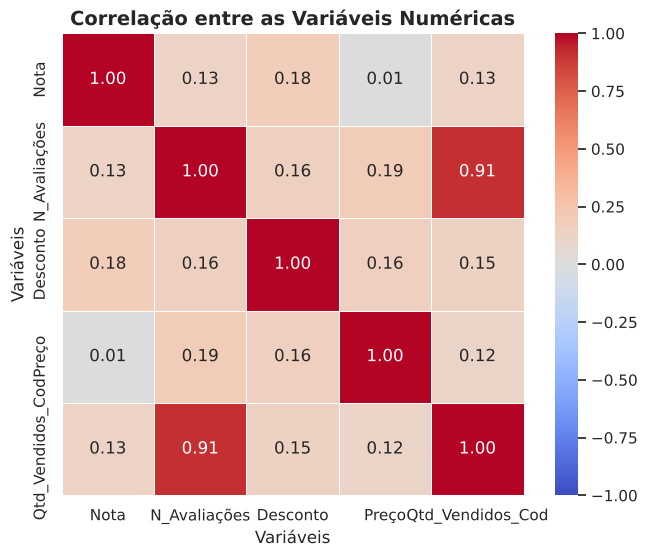

In [8]:
cols = ['Nota', 'N_Avaliações', 'Desconto', 'Preço', 'Qtd_Vendidos_Cod']
corr = df[cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
            square=True, linewidths=0.5, ax=ax)
ax.set_title('Correlação entre as Variáveis Numéricas')
ax.set_xlabel('Variáveis')
ax.set_ylabel('Variáveis')
plt.show()

**Leitura:** a relação que se destaca é **número de avaliações × quantidade vendida (≈ 0,91)** — faz sentido, pois quem compra avalia. As demais correlações são fracas (< 0,2): desconto e preço, isoladamente, explicam pouco do volume de vendas.

## 5. Gráfico de barras — marcas que mais vendem

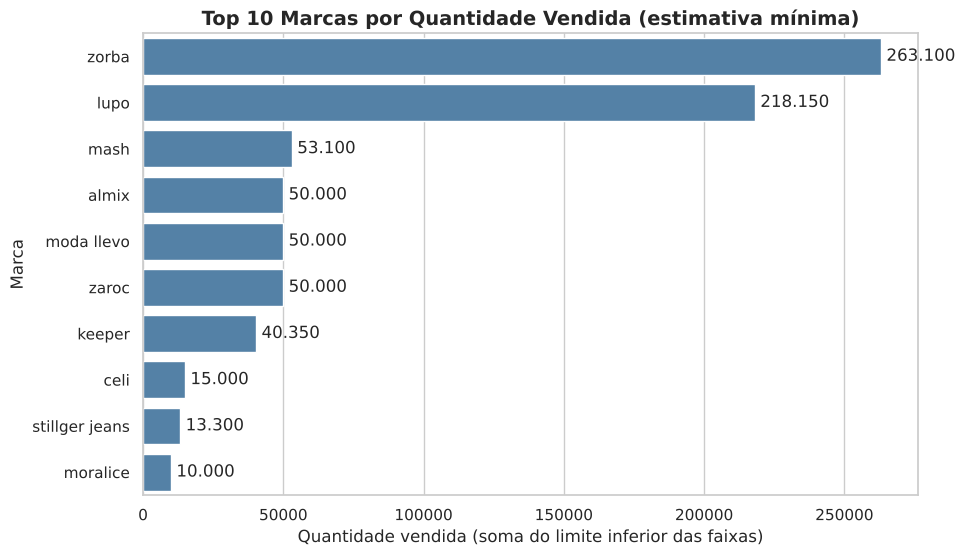

zorba responde por 30% das vendas estimadas


In [9]:
top_marcas = (df.groupby('Marca')['Qtd_Vendidos_Cod']
                .sum()
                .sort_values(ascending=False)
                .head(10))

fig, ax = plt.subplots()
sns.barplot(x=top_marcas.values, y=top_marcas.index, color='steelblue', ax=ax)
ax.set_title('Top 10 Marcas por Quantidade Vendida (estimativa mínima)')
ax.set_xlabel('Quantidade vendida (soma do limite inferior das faixas)')
ax.set_ylabel('Marca')
for i, v in enumerate(top_marcas.values):
    ax.text(v, i, f' {v:,.0f}'.replace(',', '.'), va='center')
plt.show()

share = top_marcas.iloc[0] / df['Qtd_Vendidos_Cod'].sum()
print(f"{top_marcas.index[0]} responde por {share:.0%} das vendas estimadas")

**Leitura:** as vendas são **muito concentradas** em poucas marcas — a líder (Zorba) sozinha responde por cerca de 30% do volume estimado. Essas marcas são prioridade para estoque e campanhas.

## 6. Gráfico de pizza — participação de produtos por público

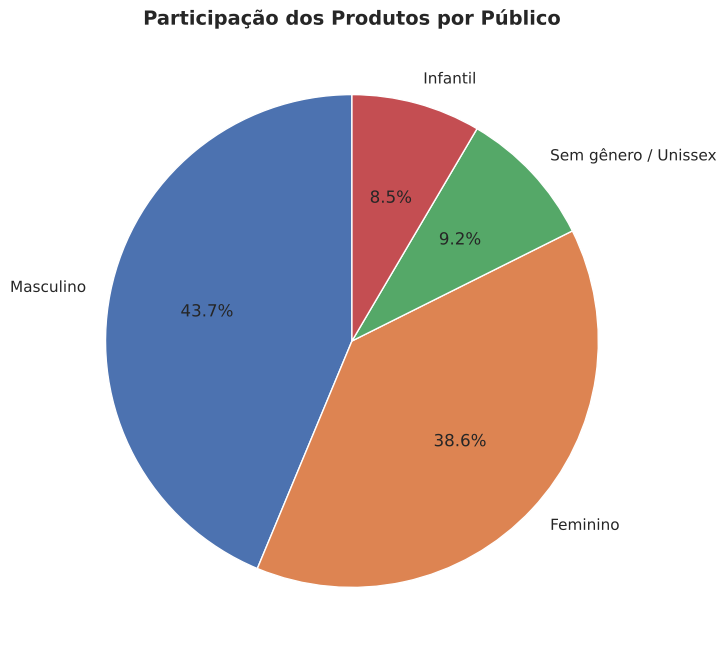

In [10]:
contagem = df['Público'].value_counts()

fig, ax = plt.subplots(figsize=(8, 8))
ax.pie(contagem, labels=contagem.index, autopct='%1.1f%%', startangle=90,
       colors=sns.color_palette('deep'), wedgeprops={'edgecolor': 'white'})
ax.set_title('Participação dos Produtos por Público')
plt.show()

**Leitura:** o catálogo é dominado por produtos **masculinos e femininos** (juntos, mais de 80%). O público infantil é pequeno — pode ser uma oportunidade de expansão ou simplesmente fora do foco do cliente.

## 7. Gráfico de densidade — preço por público

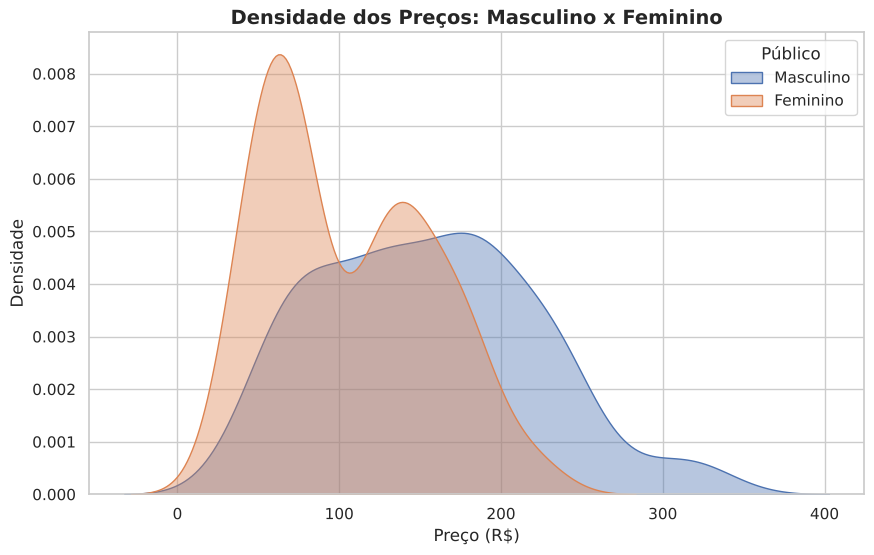

,mean,median,count
Público,,,
Feminino,105.32,79.78,114
Infantil,106.20,98.05,25
Masculino,154.97,152.91,129
Sem gênero / Unissex,146.11,166.21,27


In [11]:
fig, ax = plt.subplots()
for publico in ['Masculino', 'Feminino']:
    sns.kdeplot(df.loc[df['Público'] == publico, 'Preço'], fill=True, alpha=0.4,
                label=publico, ax=ax)
ax.set_title('Densidade dos Preços: Masculino x Feminino')
ax.set_xlabel('Preço (R$)')
ax.set_ylabel('Densidade')
ax.legend(title='Público')
plt.show()

df.groupby('Público')['Preço'].agg(['mean', 'median', 'count']).round(2)

**Leitura:** os produtos **masculinos são mais caros** (mediana ≈ R$ 153) que os femininos (mediana ≈ R$ 80). A curva feminina concentra-se em preços baixos, com cauda longa para a direita. Obs.: o KDE suaviza a distribuição — por isso é bom olhar junto com o histograma.

## 8. Gráfico de regressão — avaliações × quantidade vendida

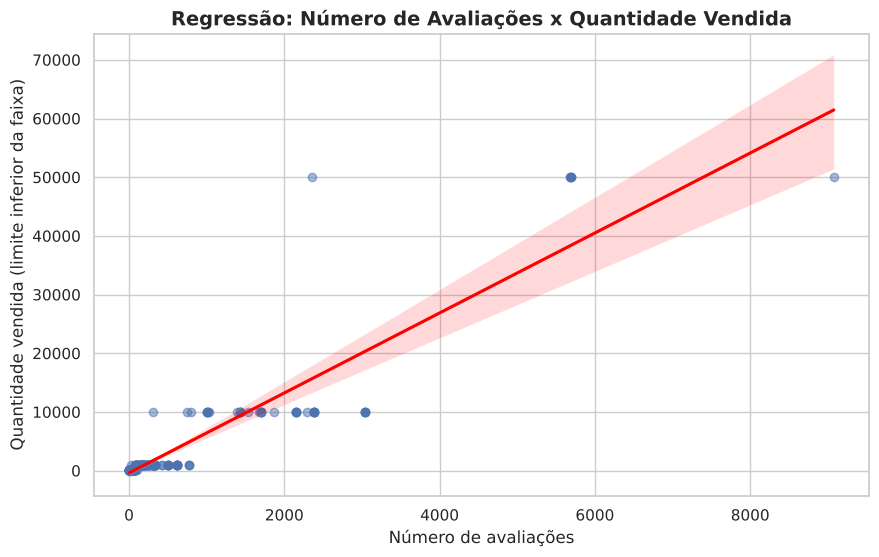

In [12]:
fig, ax = plt.subplots()
sns.regplot(data=df, x='N_Avaliações', y='Qtd_Vendidos_Cod',
            scatter_kws={'alpha': 0.5}, line_kws={'color': 'red'}, ax=ax)
ax.set_title('Regressão: Número de Avaliações x Quantidade Vendida')
ax.set_xlabel('Número de avaliações')
ax.set_ylabel('Quantidade vendida (limite inferior da faixa)')
plt.show()

**Leitura:** a reta tem inclinação positiva clara — produtos com mais avaliações vendem mais. Como `Qtd_Vendidos_Cod` vem de faixas, os pontos aparecem em "degraus" horizontais. Na prática, o número de avaliações funciona como um **bom indicador (proxy) de volume de vendas** quando o dado exato não está disponível.

## 9. Conclusões para o cliente
1. **Preço não determina satisfação**: nota e preço não têm relação — dá para trabalhar preços sem medo de afetar avaliações.
2. **Avaliações acompanham vendas**: incentivar avaliações (pós-venda) reforça a prova social dos produtos que mais vendem.
3. **Vendas concentradas em poucas marcas**: priorizar estoque e mídia dessas marcas.
4. **Desconto tem efeito fraco** sobre o volume nesta base — promoções devem ser testadas com cuidado, não aplicadas no catálogo inteiro.
5. **Catálogo focado em adulto (masculino/feminino)**; infantil é nicho pequeno. Produtos masculinos têm preço mediano bem acima dos femininos.